In [1]:
# import 4FGL DR3 catalog and look at classes and features
import numpy as np
#import astropy
from astropy.io import fits
from matplotlib import pyplot
import pandas as pd
import os
import copy

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression

try:
    import dio3
    import multi_fgl_utils as util
except:
    import sys
    sys.path.append('../lib/')
    import dio3
    import multi_fgl_utils as util

In [2]:
folder_in = '../data_in/'
folder_out = '../data_out/'
np.set_printoptions(precision=4)

scores_step1_2class_fn = folder_out + 'pars_scores_basic_2class.yaml'
all_classes_fn = folder_out + 'all_classes.yaml'

In [3]:
#fn = folder_in + '4FGL-DR3_categories.csv'
#classes_df = pd.read_csv(fn)
fn = folder_in + 'gll_psc_v29.fit'
cat_hdu = fits.open(fn)
ctab = cat_hdu[1].data 
ns = len(ctab)

fn = '../data_in/table-4LAC-DR2-h.fits'
hdu = fits.open(fn)
lach = hdu[1].data
fn = '../data_in/table-4LAC-DR2-l.fits'
hdu = fits.open(fn)
lacl = hdu[1].data
#cnames = [cat_hdu[1].header[key] for key in cat_hdu[1].header.keys() if key.startswith('TTYPE')]
cnamesl = [clm.name for clm in lach.columns]
#lac_lats = list(lach['GLAT']) + list(lacl['GLAT'])
lac_lats = lacl['GLAT']
sin_lac_lats = np.sin(np.deg2rad(lac_lats))
#mask = np.array(lacl['Counterpart_Catalog'] == 'at20g') | np.array(lacl['Counterpart_Catalog'] == 'nvss')
mask = np.ones(len(lacl), dtype=bool)
pbl = lacl['ASSOC_PROB_BAY'][mask]
plrl = lacl['ASSOC_PROB_LR'][mask]
blrl = (pbl > 0.8) & (plrl > 0.8)
ntl = sum(blrl)
print('ntl', ntl)
#mask = np.array(lach['Counterpart_Catalog'] == 'at20g') | np.array(lach['Counterpart_Catalog'] == 'nvss')
mask = np.ones(len(lach), dtype=bool)
pbh = lach['ASSOC_PROB_BAY'][mask]
plrh = lach['ASSOC_PROB_LR'][mask]
blrh = (pbh > 0.8) & (plrh > 0.8)
nth = sum(blrh)
print('nth', nth)


ntl 269
nth 2221


In [4]:
pbl[pbl < 0] = 0
pbh[pbh < 0] = 0

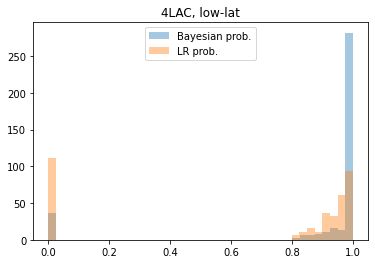

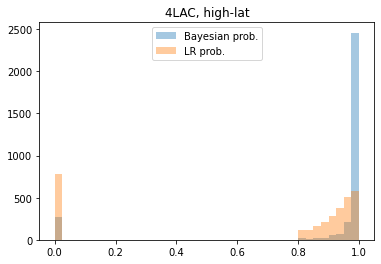

In [5]:
pyplot.figure()
pyplot.hist(pbl, alpha=0.4, bins=40, label='Bayesian prob.')
pyplot.hist(plrl, alpha=0.4, bins=40, label='LR prob.')
pyplot.title('4LAC, low-lat')
pyplot.legend(loc='upper center')

pyplot.figure()
pyplot.hist(pbh, alpha=0.4, bins=40, label='Bayesian prob.')
pyplot.hist(plrh, alpha=0.4, bins=40, label='LR prob.')
pyplot.title('4LAC, high-lat')
pyplot.legend(loc='upper center')

#fn = '../plots/assoc/4LAC_low_lat_probs.pdf'
#pyplot.savefig(fn)

In [6]:
cnames = [cat_hdu[1].header[key] for key in cat_hdu[1].header.keys() if key.startswith('TTYPE')]
#cat_df = pd.DataFrame(columns=cnames, index=range(ns))
if 0:
    for name in cnames:
        if cat_hdu[1].data[name].shape == (ns,):
            cat_df[name] = cat_hdu[1].data[name]
        else:
            pass
            #cat_df.drop(columns=[name,])
print(cnames)

['Source_Name', 'DataRelease', 'RAJ2000', 'DEJ2000', 'GLON', 'GLAT', 'Conf_68_SemiMajor', 'Conf_68_SemiMinor', 'Conf_68_PosAng', 'Conf_95_SemiMajor', 'Conf_95_SemiMinor', 'Conf_95_PosAng', 'ROI_num', 'Extended_Source_Name', 'Signif_Avg', 'Pivot_Energy', 'Flux1000', 'Unc_Flux1000', 'Energy_Flux100', 'Unc_Energy_Flux100', 'SpectrumType', 'PL_Flux_Density', 'Unc_PL_Flux_Density', 'PL_Index', 'Unc_PL_Index', 'LP_Flux_Density', 'Unc_LP_Flux_Density', 'LP_Index', 'Unc_LP_Index', 'LP_beta', 'Unc_LP_beta', 'LP_SigCurv', 'LP_EPeak', 'Unc_LP_EPeak', 'PLEC_Flux_Density', 'Unc_PLEC_Flux_Density', 'PLEC_IndexS', 'Unc_PLEC_IndexS', 'PLEC_ExpfactorS', 'Unc_PLEC_ExpfactorS', 'PLEC_Exp_Index', 'Unc_PLEC_Exp_Index', 'PLEC_SigCurv', 'PLEC_EPeak', 'Unc_PLEC_EPeak', 'Npred', 'Flux_Band', 'Unc_Flux_Band', 'nuFnu_Band', 'Sqrt_TS_Band', 'Variability_Index', 'Frac_Variability', 'Unc_Frac_Variability', 'Signif_Peak', 'Flux_Peak', 'Unc_Flux_Peak', 'Time_Peak', 'Peak_Interval', 'Flux_History', 'Unc_Flux_History',

In [7]:
mask1 = (np.array([ass.strip() for ass in ctab['ASSOC1']]) != '')
mask2 = (np.array([ass.strip() for ass in ctab['ASSOC2']]) != '')
mask = mask1 | mask2
hl_mask = np.abs(ctab['GLAT'][mask]) > 10
ll_mask = np.abs(ctab['GLAT'][mask]) < 10
vs = np.sin(np.deg2rad(ctab['GLAT'][mask]))
pb = np.array(ctab['ASSOC_PROB_BAY'][mask])
plr = np.array(ctab['ASSOC_PROB_LR'][mask])

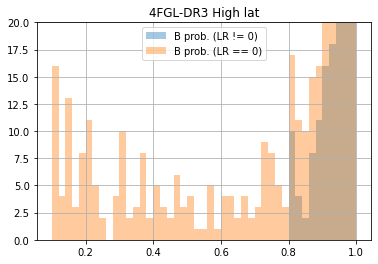

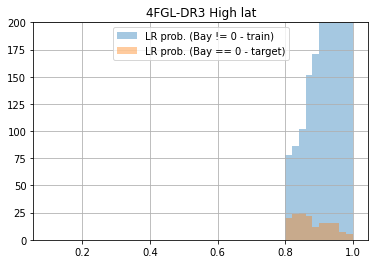

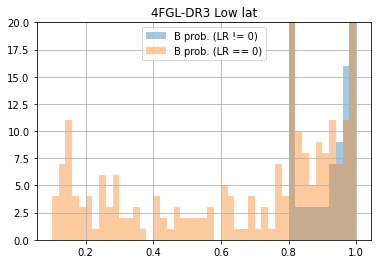

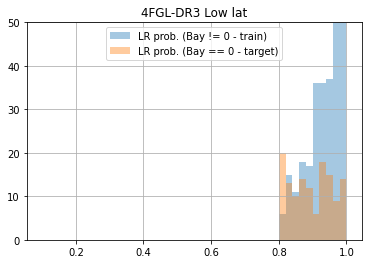

In [8]:
ltitle = ['High lat', 'Low lat']
for i, lmask in enumerate([hl_mask, ll_mask]):
    pyplot.figure()
    bins = np.arange(0.1, 1.01, 0.02)
    pyplot.hist(pb[(plr!=0.) & lmask], alpha=0.4, bins=bins, label='B prob. (LR != 0)')
    pyplot.hist(pb[(plr==0.) & lmask], alpha=0.4, bins=bins, label='B prob. (LR == 0)')
    pyplot.title('4FGL-DR3 ' + ltitle[i])
    pyplot.legend(loc='upper center')
    pyplot.ylim(0, 20)
    pyplot.grid()
    
    pyplot.figure()
    pyplot.hist(plr[(pb!=0.) & lmask], alpha=0.4, bins=bins, label='LR prob. (Bay != 0 - train)')
    pyplot.hist(plr[(pb==0.) & lmask], alpha=0.4, bins=bins, label='LR prob. (Bay == 0 - target)')
    pyplot.title('4FGL-DR3 ' + ltitle[i])
    pyplot.legend(loc='upper center')
    if i == 0:
        pyplot.ylim(0, 200)
    else:
        pyplot.ylim(0, 50)
    pyplot.grid()
    #fn = '../plots/assoc/NVSS_probs.pdf'
    #pyplot.savefig(fn)

In [9]:
pyplot.hist?

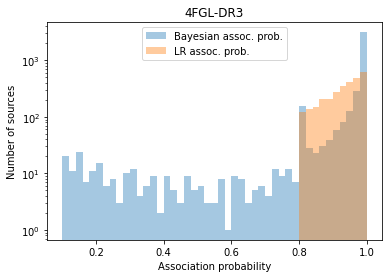

In [10]:
lmask = np.ones(len(pb), dtype=bool)
#lmask = hl_mask
pyplot.figure()
bins = np.arange(0.1, 1.01, 0.02)
pyplot.hist(pb[lmask], alpha=0.4, bins=bins, label='Bayesian assoc. prob.', log=True)
pyplot.hist(plr[lmask], alpha=0.4, bins=bins, label='LR assoc. prob.', log=True)
pyplot.title('4FGL-DR3')
pyplot.legend(loc='upper center')
#pyplot.ylim(0, 20)
#pyplot.grid()
pyplot.xlabel('Association probability')
pyplot.ylabel('Number of sources')
fn = '../plots/assoc/BvsLR_assoc_probs.pdf'
pyplot.savefig(fn)

Text(0.5, 1.0, 'Assoc., Bay = 0, 4FGL-DR3')

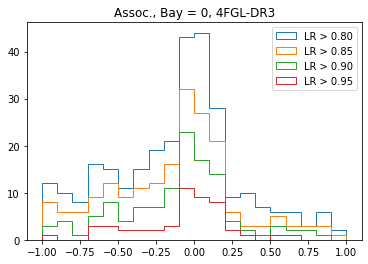

In [11]:
pyplot.figure()
bins = np.linspace(-1, 1., 21)
#pyplot.hist(pb, alpha=0.4, bins=40, label='Bayesian prob.')
for plrt in np.arange(0.8, 0.96, 0.05):
    mask = (pb == 0.) & (plr > plrt) #& (plr < plrt + 0.05)
    pyplot.hist(vs[mask], bins=bins, histtype='step', label='LR > %.2f' % plrt)
pyplot.legend()
pyplot.title('Assoc., Bay = 0, 4FGL-DR3')